# Fase 2 — Ingeniería de características y partición

**Bioactive AI** · Equipo 7 · Maestría en Inteligencia Artificial Aplicada (TC5035.10)

Convierte las **mediciones de actividad** en la matriz del modelo de la fase 2. Es el equivalente, para la actividad en el sistema nervioso, de lo que el [Avance 2](../notebooks/02_Feature_Eng.ipynb) hizo con la permeabilidad, y parte del [EDA de actividad](../notebooks/01b_EDA_actividad_snc.ipynb).

## La diferencia con la fase 1, que organiza todo el notebook

En la fase 1 cada fila era un compuesto y la etiqueta venía dada: `bbb_class`. Aquí ninguna de las dos cosas es cierta.

1. **El archivo trae mediciones, no compuestos.** 202,647 filas, varias por la misma combinación de compuesto y diana, así que la unidad del modelo —el **par compuesto-diana**— hay que construirla.
2. **La etiqueta no existe en el archivo.** No hay columna que diga «activo». Hay concentraciones, y convertirlas en etiqueta exige un umbral que, como se ve en §4, **no es estimable con estos datos**: se elige y se declara.

De ahí la decisión que da forma a este notebook: **no se guarda una etiqueta, se guarda el intervalo donde cae la potencia**, y la etiqueta binaria se deriva de él ([2.10](../docs/decisiones.md#d2-10)).

## Qué produce

| Artefacto | Qué trae | Filas |
|:--|:--|--:|
| `fase2_pares.parquet` | identidad del par, metadatos y las cuatro columnas objetivo | 70,384 |
| `fase2_descriptores.parquet` | los 217 descriptores 2D de RDKit, **por compuesto** | 59,781 |
| `fase2_descriptores_limpios.parquet` | los mismos tras la limpieza, 201 columnas | 59,781 |

Los construye `scripts/construir_pares_fase2.py` desde `src/data_prep/pares_fase2.py`; aquí se cargan y se analizan. El código vive fuera del notebook a propósito: así los tests lo cubren (`tests/test_pares_fase2.py`) y la matriz se puede reconstruir sin abrir Jupyter.

## Qué decide, y qué deja abierto

**Decide** el formato del objetivo ([2.10](../docs/decisiones.md#d2-10)), la llave del par y los estratos de procedencia ([2.3](../docs/decisiones.md#d2-3)), y la partición agrupada ([2.7](../docs/decisiones.md#d2-7)).

**Deja abierto**, y lo dice en cada caso: dónde se corta «activo» ([2.3](../docs/decisiones.md#d2-3), vigente en 10 µM y reversible porque el objetivo se guarda como intervalo), si se clasifica o se predice potencia ([2.9](../docs/decisiones.md#d2-9), del Avance 4) y qué dianas son prioritarias ([2.2](../docs/decisiones.md#d2-2)).

## 1. Preparación

In [1]:
import sys, warnings, platform
warnings.filterwarnings("ignore")
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# Se inserta la raíz y no `src/`, al contrario del notebook 02, porque
# `src.data_prep.pares_fase2` importa de `src.features` y necesita el paquete
# completo. Es la misma ruta que usan los tests.
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, rdkit

from src.data_prep.pares_fase2 import (CINCO_CATEGORIAS, RANGO_POTENCIA,
                                       etiqueta_binaria, grupos_de_pares)
from src.data_prep.splits import grupos_cv, verificar_fuga
from src.features.molecular import morgan_plegado, a_mol

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (8, 4.2)})
RNG = 20261017

print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"scikit-learn {sklearn.__version__} · RDKit {rdkit.__version__}")
print(f"Semilla {RNG}")

Python 3.14.3 · pandas 3.0.6 · numpy 2.5.3
scikit-learn 1.9.1 · RDKit 2026.03.6
Semilla 20261017


Las versiones se imprimen porque entre ellas cambian cifras en el tercer decimal, y entre sistemas operativos cambian más: la fase 1 midió 0.481 de MCC en Linux, 0.489 en macOS con Python 3.12 y 0.497 con 3.14 para el mismo modelo. Nada que dependa de una sola corrida se decide aquí.

In [2]:
# `data/processed/` no se versiona (lo excluye el `.gitignore`), así que estos
# dos archivos hay que generarlos antes de ejecutar el notebook (~5 minutos):
#
#     python scripts/construir_pares_fase2.py
PROCESADOS = RAIZ / "data/processed"
pares = pd.read_parquet(PROCESADOS / "fase2_pares.parquet")
desc = pd.read_parquet(PROCESADOS / "fase2_descriptores_limpios.parquet")

print(f"pares            {len(pares):>8,}")
print(f"compuestos       {pares['esqueleto'].nunique():>8,}")
print(f"dianas           {pares['target_gene'].nunique():>8,}")
print(f"descriptores     {desc.shape[1] - 1:>8,}  (de 217)")
pares.head(3)

pares              70,384
compuestos         59,532
dianas                 26
descriptores          201  (de 217)


,esqueleto,target_gene,pActividad,n_exactas,n_mediciones,rango_exactas,diana_categoria,andamio,smiles,estrato,n_referencias,n_ensayos,limite_inferior,limite_superior,conflicto,activo_10um,activo_1um,grupo_cv
0,SRKMMWQNEAUSLE,DRD2,5.008774,1,1,0.000000,Parkinson,c1cnc(N2CCN(Cc3cccc4c3Cc3ccccc3-4)CC2)nc1,c1cnc(N2CCN(Cc3cccc4c3Cc3ccccc3-4)CC2)nc1,solo_chembl,1,1,5.008774,5.008774,False,True,False,ESRKMMWQNEAUSLE
1,WDIPTEIUSFFSDV,PPARG,7.697240,2,2,0.993161,Alzheimer,c1ccccc1,CC(/C=C/C(F)=C(/C)c1cc(C(C)(C)C)cc(C(C)(C)C)c1...,solo_chembl,1,2,7.697240,7.697240,False,True,True,EALYNCZNDIQEVRV
2,UACZNFHCLLGRTD,NOS2,6.242328,6,6,1.255273,Neuroinflamación,C1=NCCC1,CCCCCC1N=C(N)CC1C.Cl,solo_chembl,2,2,6.242328,6.242328,False,True,True,EODHCTXKNWHHXJC


## 2. De mediciones a pares: qué se guarda y por qué

El objetivo son **cuatro columnas**, no una:

| Columna | Qué es |
|:--|:--|
| `pActividad` | la potencia como número, 6 − log10 µM. Coincide con el pChEMBL donde este existe |
| `limite_inferior`, `limite_superior` | el intervalo donde cae la potencia, con ±∞ cuando no hay cota |
| `activo_10um`, `activo_1um` | la etiqueta binaria, **derivada** del intervalo |

El motivo es una lección de la fase 1 aplicada al revés. El Avance 2 seleccionó sus 171 columnas sobre la matriz transformada con Yeo-Johnson y congeló ese artefacto, así que cambiar la transformación obliga a repetir la selección y a reejecutar el notebook. Guardar solo `activo_10um` tendría el mismo defecto: adoptar la regresión de la [2.9](../docs/decisiones.md#d2-9) obligaría a reconstruir todo.

Con el intervalo guardado, **el umbral pasa a ser una decisión de lectura**: los tres modelos candidatos leen el mismo archivo.

In [3]:
estado = pd.DataFrame({
    "pares": [
        len(pares),
        pares["pActividad"].notna().sum(),
        pares["pActividad"].isna().sum(),
        int(pares["conflicto"].sum()),
        int((pares["limite_inferior"] > pares["limite_superior"]).sum()),
    ]},
    index=["todos", "con potencia (alguna medición exacta)", "solo con cotas",
           "en conflicto", "con intervalo vacío"])
estado["del total"] = (estado["pares"] / len(pares)).map("{:.1%}".format)
estado

,pares,del total
todos,70384,100.0%
con potencia (alguna medición exacta),57832,82.2%
solo con cotas,12552,17.8%
en conflicto,1126,1.6%
con intervalo vacío,15,0.0%


**Los 12,552 pares que solo tienen cotas no son datos faltantes.** Un `> 10 µM` dice que el ensayo llegó a esa concentración sin ver efecto: es evidencia de inactividad, y la mitad de la clase negativa existe únicamente así. Borrarlos —que es lo que hace una regresión sobre mediciones exactas— quita el 49.4% de los negativos y no al azar, porque el 98% de los activos sí tiene medición exacta. Es el argumento de la [2.9](../docs/decisiones.md#d2-9).

### 2.1 El intervalo reproduce la regla del diccionario

La sección 7 del diccionario de la patrocinadora dice que un censurado «solo sirve como negativo si el límite es igual o mayor que el umbral de activo que se use». En escala de potencia eso no hay que programarlo: un `> L µM` es una **cota superior**, así que «inactivo con umbral T» es `limite_superior ≤ 6 − log10 T`.

In [4]:
demo = pd.DataFrame({
    "medición":        ["IC50 = 0.3 µM", "IC50 = 25 µM", "IC50 = 10 µM",
                        "IC50 > 10 µM",  "IC50 > 1 µM",  "IC50 > 100 µM"],
    "limite_inferior": [6 - np.log10(0.3), 6 - np.log10(25), 6 - np.log10(10),
                        -np.inf, -np.inf, -np.inf],
    "limite_superior": [6 - np.log10(0.3), 6 - np.log10(25), 6 - np.log10(10),
                        6 - np.log10(10), 6 - np.log10(1), 6 - np.log10(100)],
})
for umbral in (10.0, 1.0):
    demo[f"activo a {umbral:g} µM"] = etiqueta_binaria(demo, umbral).map(
        {True: "activo", False: "inactivo"}).fillna("sin decidir")
demo.round(2)

,medición,limite_inferior,limite_superior,activo a 10 µM,activo a 1 µM
0,IC50 = 0.3 µM,6.52,6.52,activo,activo
1,IC50 = 25 µM,4.60,4.60,inactivo,inactivo
2,IC50 = 10 µM,5.00,5.00,activo,inactivo
3,IC50 > 10 µM,-inf,5.00,inactivo,inactivo
4,IC50 > 1 µM,-inf,6.00,sin decidir,inactivo
5,IC50 > 100 µM,-inf,4.00,inactivo,inactivo


Las tres filas que importan:

- **`IC50 = 10 µM` con umbral de 10 µM sale activo** y **`IC50 > 10 µM` sale inactivo**, aunque los dos tengan la misma relación numérica con el corte. Lo que los distingue es que el censurado no tiene cota inferior. Resolver el empate a favor de activo mueve 409 pares, porque los valores redondos son frecuentes en estos ensayos.
- **`IC50 > 1 µM` queda sin decidir con 10 µM y es inactivo con 1 µM.** Eso *es* la regla del diccionario, obtenida como consecuencia y no como caso especial.

## 3. La etiqueta: dos umbrales, y lo que cada uno cuesta

In [5]:
resumen = []
for umbral, col in ((10.0, "activo_10um"), (1.0, "activo_1um")):
    s = pares[col]
    resumen.append({
        "umbral": f"{umbral:g} µM",
        "pChEMBL": f"≥ {6 - np.log10(umbral):.0f}",
        "con etiqueta": s.notna().sum(),
        "activos": int(s.sum()),
        "% activos": f"{s.mean():.1%}",
        "sin decidir": int(s.isna().sum()),
        "razón de clases": f"{s.sum() / (s.notna().sum() - s.sum()):.2f}:1",
    })
pd.DataFrame(resumen).set_index("umbral")

,pChEMBL,con etiqueta,activos,% activos,sin decidir,razón de clases
umbral,,,,,,
10 µM,≥ 5,67736,49332,72.8%,2648,2.68:1
1 µM,≥ 6,69632,34922,50.2%,752,1.01:1


Con 10 µM quedan 2,648 pares sin decidir y la clase está desbalanceada 2.7:1; con 1 µM el conjunto queda casi balanceado y solo 752 pares sin decidir, porque un umbral más estricto convierte más censurados en negativos seguros. Es la misma regla atando los dos extremos que describe la [2.3](../docs/decisiones.md#d2-3).

**El corte vigente es 10 µM y es una convención del protocolo de tamizaje, no un hallazgo.** Es la concentración a la que los ensayos dejaron de mirar: el 67.4% de las 54,377 mediciones censuradas del archivo lo está exactamente en 10 µM, y el comentario de ChEMBL de las filas declaradas inactivas lo dice literalmente («Inhibition < 50% @ 10 uM»). Lo que sí es medible favorece **1 µM** —más censurados aprovechables, clases casi balanceadas y más pares etiquetados—, así que 10 µM se conserva como principal por comparabilidad con el diccionario y los dos se reportan al lado ([2.3](../docs/decisiones.md#d2-3)).

## 4. Lo que la etiqueta esconde, y es la sección que hay que leer

Tres cosas que un número agregado tapa. Todas se reportan junto a cualquier métrica, y las tres salen de este mismo artefacto.

### 4.1 El mismo umbral no mide lo mismo en cada diana

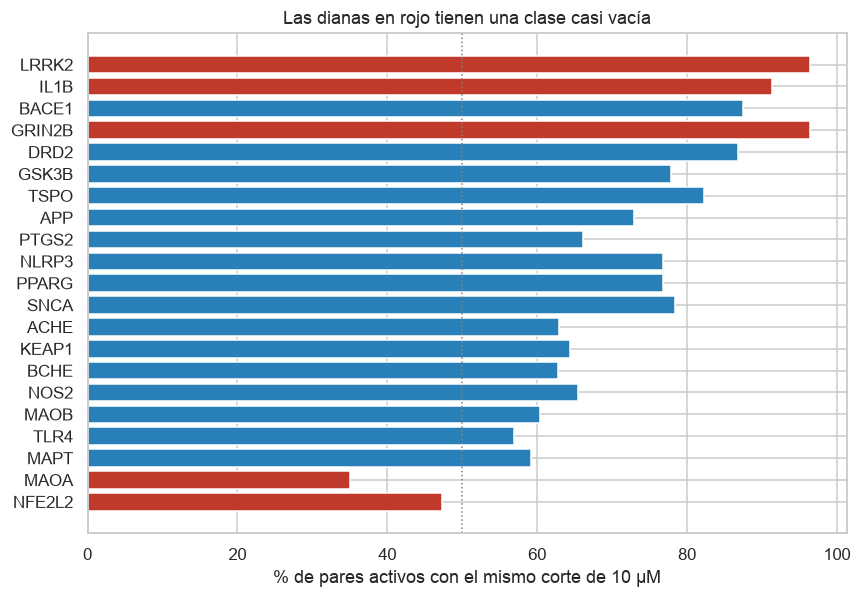

de 35.0% (MAOA) a 96.5% (LRRK2)
mediana de potencia: de 5.02 a 7.40  (241×)


In [6]:
por_diana = (pares.groupby("target_gene")
             .agg(pares=("activo_10um", "size"),
                  activos=("activo_10um", "mean"),
                  potencia_mediana=("pActividad", "median"))
             .sort_values("potencia_mediana", ascending=False))
grandes = por_diana[por_diana["pares"] >= 200]

fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(grandes.index, grandes["activos"] * 100,
        color=np.where(grandes["activos"] > 0.9, "#c0392b",
                       np.where(grandes["activos"] < 0.5, "#c0392b", "#2980b9")))
ax.axvline(50, color="grey", ls=":", lw=1)
ax.set_xlabel("% de pares activos con el mismo corte de 10 µM")
ax.set_title("Las dianas en rojo tienen una clase casi vacía")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

print(f"de {grandes['activos'].min():.1%} ({grandes['activos'].idxmin()})"
      f" a {grandes['activos'].max():.1%} ({grandes['activos'].idxmax()})")
print(f"mediana de potencia: de {grandes['potencia_mediana'].min():.2f}"
      f" a {grandes['potencia_mediana'].max():.2f}"
      f"  ({10 ** (grandes['potencia_mediana'].max() - grandes['potencia_mediana'].min()):,.0f}×)")

**Con un solo corte, `LRRK2` queda con el 96.5% de sus pares activos y `MAOA` con el 35.0%.** La etiqueta no mide lo mismo: en `LRRK2` es casi constante y como objetivo de clasificación aporta poco, mientras que en `MAOA` separa de verdad.

La causa es que la potencia intrínseca de cada diana difiere en **dos órdenes de magnitud**, y el corte es el mismo para todas. Y los experimentadores ya lo sabían: el límite de censura que eligieron va de 1 µM en `LRRK2` a 100 µM en `NOS2`, en el mismo orden. Se intentó usar esa moda como umbral por diana y **falló**: está condicionada al fracaso —es el techo de los ensayos que no encontraron nada— y dejaba seis dianas con 93–96% de activos, peor que el corte global ([2.3](../docs/decisiones.md#d2-3)).

Mientras el corte siga siendo global, esta figura acompaña cualquier cifra agregada.

### 4.2 La procedencia está confundida con la etiqueta

La fuente **no es un atributo del par**: 827 de los 828 pares de CMAUP comparten par con otra fuente, así que «activos de CMAUP» describiría un grupo que casi no existe. Por eso se reporta en **estratos disjuntos por procedencia de la evidencia**.

In [7]:
estratos = (pares.groupby("estrato")
            .agg(pares=("activo_10um", "size"),
                 activos=("activo_10um", "mean"),
                 potencia_mediana=("pActividad", "median"))
            .sort_values("pares", ascending=False))
estratos["% activos"] = (estratos["activos"] * 100).round(1)
estratos.drop(columns="activos").round(2)

,pares,potencia_mediana,% activos
estrato,,,
solo_chembl,66324,6.38,75.8
solo_npass,2231,4.65,14.0
mixto,1828,4.99,40.0
solo_cmaup,1,4.65,0.0


**63 puntos de diferencia entre `solo_chembl` y `solo_npass`**, y no es un artefacto del etiquetado: es química real. La mediana de potencia de las mediciones de NPASS es 6.56 µM contra 0.335 µM en ChEMBL, veinte veces, así que **el corte de 10 µM cae casi en la mediana de los naturales y a treinta veces de la de ChEMBL**. Para los naturales la etiqueta la decide el ruido de medición; para ChEMBL es estable.

Eso es la preocupación de la patrocinadora sobre comparabilidad, en la forma que sí se puede medir —no la que ella nombró, que era el tejido, y que no se puede comprobar porque la columna está vacía en las 108,640 filas de la ruta `cns_target`—.

**Consecuencia operativa:** la procedencia nunca entra como característica, porque un compuesto nuevo no la tiene, y el desempeño se reporta por estrato. Si el control de atajo del [#32](https://github.com/AntonioVazquezMartinez/Bioactive-AI/issues/32) —un modelo que solo ve procedencia, sin química— se acerca al modelo real, la fuente está filtrando la etiqueta.

### 4.3 La dispersión entre mediciones del mismo par

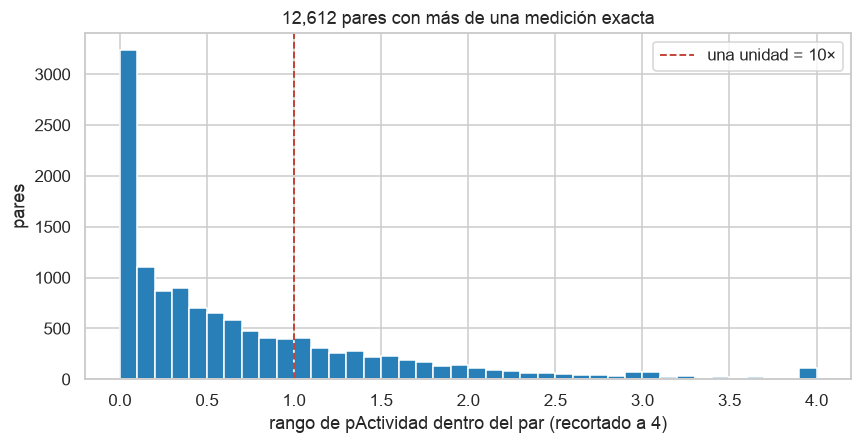

mediana 0.43 · p90 1.80
pares que discrepan más de 10×: 3,222 (25.5%)


In [8]:
multi = pares[pares["n_exactas"] > 1]
fig, ax = plt.subplots()
ax.hist(multi["rango_exactas"].clip(upper=4), bins=40, color="#2980b9")
ax.axvline(1, color="#c0392b", ls="--", lw=1.2, label="una unidad = 10×")
ax.set_xlabel("rango de pActividad dentro del par (recortado a 4)")
ax.set_ylabel("pares"); ax.legend()
ax.set_title(f"{len(multi):,} pares con más de una medición exacta")
plt.tight_layout(); plt.show()

print(f"mediana {multi['rango_exactas'].median():.2f} · "
      f"p90 {multi['rango_exactas'].quantile(.9):.2f}")
print(f"pares que discrepan más de 10×: {(multi['rango_exactas'] > 1).sum():,}"
      f" ({(multi['rango_exactas'] > 1).mean():.1%})")

Un cuarto de los pares con varias mediciones discrepan más de **10×** entre ellas, y el 98.6% de esos casos tiene el mismo formato de ensayo anotado —o, más exactamente, **ninguno**, porque la columna está vacía—. No se puede saber si el tejido lo explica.

**Por eso la agregación usa la mediana y no el valor más potente.** El máximo sesga hacia la clase positiva, y con la mediana la dispersión deja de ser «conflicto»: dos mediciones a los lados del corte son ruido de medición, no contradicción. Así los conflictos bajan de 1,784 a 1,126, y de esos solo 15 dan un intervalo vacío. La información no se pierde —vive en `rango_exactas`— así que un análisis de robustez puede excluir los pares dispersos sin volver a leer el archivo.

## 5. Las características

Las mismas de la fase 1, por la [1.3](../docs/decisiones.md#d1-3): descriptores 2D de RDKit más Morgan/ECFP4 de 2048 bits. Lo que cambia es la unidad: **se calculan por compuesto, no por par**, y el modelado une por `smiles`. Guardarlos por par repetiría cada fila 1.18 veces en promedio, y mucho más para los compuestos medidos contra varias dianas.

In [9]:
print(f"descriptores utilizables: {desc.shape[1] - 1} de 217")
print(f"compuestos:              {len(desc):,}")

# Qué se descartó y por qué, recalculado aquí para que la cifra tenga corrida detrás
crudos = pd.read_parquet(PROCESADOS / "fase2_descriptores.parquet")
fuera = sorted(set(crudos.columns) - set(desc.columns))
print(f"\ndescartados ({len(fuera)}): {', '.join(fuera)}")

descriptores utilizables: 201 de 217
compuestos:              59,781

descartados (16): BCUT2D_CHGHI, BCUT2D_CHGLO, BCUT2D_LOGPHI, BCUT2D_LOGPLOW, BCUT2D_MRHI, BCUT2D_MRLOW, BCUT2D_MWHI, BCUT2D_MWLOW, Ipc, MaxAbsPartialCharge, MaxPartialCharge, MinAbsPartialCharge, MinPartialCharge, SMR_VSA8, SlogP_VSA9, fr_diazo


Quedan **201 de 217**, dos menos que los 203 de la fase 1. No es un criterio distinto: es el mismo `limpiar_descriptores`, sobre otro conjunto de compuestos, así que cambian las columnas que salen constantes o no finitas.

Los 16 que se van son de tres clases. Los cuatro `PartialCharge` y los ocho `BCUT2D_*` dependen de la asignación de cargas parciales de Gasteiger, que no converge para todas las moléculas y devuelve `NaN`; `Ipc` se desborda en float32 para moléculas grandes, que aquí abundan más que en el conjunto de permeabilidad; y `SMR_VSA8`, `SlogP_VSA9` y `fr_diazo` son constantes en estos 59,781 compuestos.

### 5.1 Correlación y asimetría

No se vuelve a medir qué transformación conviene: la [1.5](../docs/decisiones.md#d1-5) ya lo midió con validación cruzada agrupada y tres semillas, y el resultado fue que **entre las tres formas de escalar la medición no distingue**, que la razón para escalar es la convergencia —sin escalar la regresión logística agota sus iteraciones— y que Yeo-Johnson es la única con un motivo medido para evitarla. Aquí solo se comprueba que el diagnóstico de la fase 1 también describe esta matriz.

In [10]:
X = desc.drop(columns="smiles")
corr = X.corr().abs()
triangulo = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
muy_correlacionados = (triangulo > 0.95).sum().sum()
asimetria = X.skew().abs()

print(f"pares de descriptores con |r| > 0.95:  {muy_correlacionados:,}")
print(f"descriptores con |asimetría| > 2:      {(asimetria > 2).sum()} de {X.shape[1]}")
print(f"amplitud de los rangos: de {(X.max() - X.min()).min():.3g}"
      f" a {(X.max() - X.min()).max():,.0f}")

pares de descriptores con |r| > 0.95:  114
descriptores con |asimetría| > 2:      150 de 201
amplitud de los rangos: de 0.945 a 11,374


El mismo cuadro de la fase 1, y más marcado: los rangos difieren en varios órdenes de magnitud, así que un modelo lineal trataría al descriptor más amplio como si pesara miles de veces más por sus unidades y no por su contenido. **Los árboles son indiferentes** —solo miran el orden— así que reciben la matriz sin transformar, y la regresión logística lleva min–max como punto de partida.

### 5.2 Morgan/ECFP4

`radius=2` da ECFP4, porque el nombre lleva el diámetro. Se usa `rdFingerprintGenerator` y no el `GetMorganFingerprintAsBitVect` deprecado.

In [11]:
mols = [a_mol(s) for s in desc["smiles"]]
huellas = morgan_plegado([m for m in mols if m is not None], radio=2, n_bits=2048)
print(f"huellas: {huellas.shape[0]:,} × {huellas.shape[1]:,}")

ocupacion = huellas.sum(axis=0)
densidad = huellas.sum(axis=1)
print(f"bits nunca activados:        {(ocupacion == 0).sum():,}")
print(f"bits en más del 50% de las moléculas: {(ocupacion > 0.5 * len(huellas)).sum():,}")
print(f"bits activos por molécula:   mediana {np.median(densidad):.0f}"
      f" · p90 {np.percentile(densidad, 90):.0f}")

huellas: 59,781 × 2,048
bits nunca activados:        0
bits en más del 50% de las moléculas: 13
bits activos por molécula:   mediana 52 · p90 66


## 6. La partición: agrupada por estructura, nunca aleatoria

La [1.2](../docs/decisiones.md#d1-2) lo fijó para la fase 1 con una razón medida: una partición aleatoria infla los resultados entre 7 y 13 puntos, porque deja análogos casi idénticos a los dos lados y el modelo memoriza el andamiaje en lugar de generalizar.

Aquí hay un motivo adicional que no existía en la fase 1. La patrocinadora había reservado un 10% **al azar**, y en la reunión del 15 de octubre aceptó el argumento y entregó el archivo completo para que el equipo rehiciera la partición ([2.6](../docs/decisiones.md#d2-6)). Su única condición fue que se reserve una prueba que el modelo nunca vea.

El grupo es el **esqueleto de conectividad unido al andamio de Bemis-Murcko**, salvo en los acíclicos: todos comparten el marcador `<aciclico>`, y unirlos por ahí los fundiría en un solo grupo gigante.

In [12]:
grupos = pares["grupo_cv"].to_numpy()
tam = pd.Series(grupos).value_counts()
print(f"grupos: {len(tam):,} para {len(pares):,} pares")
print(f"  mediana {tam.median():.0f} pares por grupo · p99 {tam.quantile(.99):.0f}"
      f" · máximo {tam.max():,}")
print(f"  grupos de un solo par: {(tam == 1).sum():,} ({(tam == 1).mean():.1%})")

grupos: 24,230 para 70,384 pares
  mediana 1 pares por grupo · p99 28 · máximo 1,255
  grupos de un solo par: 14,492 (59.8%)


In [13]:
from sklearn.model_selection import StratifiedGroupKFold

etiquetados = pares["activo_10um"].notna()
y = pares.loc[etiquetados, "activo_10um"].astype(int).to_numpy()
g = pares.loc[etiquetados, "grupo_cv"].to_numpy()

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG)
filas = []
for i, (ajuste, prueba) in enumerate(cv.split(np.zeros(len(y)), y, g), 1):
    filas.append({"pliegue": i, "ajuste": len(ajuste), "prueba": len(prueba),
                  "% activos en prueba": f"{y[prueba].mean():.1%}",
                  "grupos compartidos": len(set(g[ajuste]) & set(g[prueba]))})
pd.DataFrame(filas).set_index("pliegue")

,ajuste,prueba,% activos en prueba,grupos compartidos
pliegue,,,,
1,54189,13547,72.8%,0
2,54188,13548,72.8%,0
3,54189,13547,72.8%,0
4,54188,13548,72.8%,0
5,54190,13546,72.8%,0


**Cero grupos compartidos en los cinco pliegues**, que es la propiedad que hace comparable la evaluación, y la proporción de activos se mantiene estable porque la estratificación la respeta.

In [14]:
# La misma comprobación con la función del proyecto, que mira andamio y esqueleto
from src.data_prep.splits import SIN_ANDAMIO

_, prueba_idx = next(cv.split(np.zeros(len(y)), y, g))

marca = pares.loc[etiquetados].copy()
marca["particion"] = "entrenamiento"
marca.iloc[prueba_idx, marca.columns.get_loc("particion")] = "prueba"
marca["andamio"] = marca["andamio"].fillna(SIN_ANDAMIO)
marca["y"] = y

informe = verificar_fuga(marca)
print(f"sin fuga: {informe['sin_fuga']}")
print(f"  andamios cruzados   {informe['andamios_cruzados']}")
print(f"  esqueletos cruzados {informe['esqueletos_cruzados']}")
print(f"  tamaños  {informe['tamanos']}")
print(f"  balance  {informe['balance']}")

sin fuga: True
  andamios cruzados   0
  esqueletos cruzados 0
  tamaños  {'entrenamiento': 54189, 'prueba': 13547}
  balance  {'entrenamiento': 0.7283, 'prueba': 0.7283}


## 7. Qué queda guardado, y qué decide el modelado

Los tres artefactos de `data/processed/` los produce `scripts/construir_pares_fase2.py`, y no se versionan porque el `.gitignore` excluye esa carpeta: hay que generarlos antes de ejecutar este notebook, que no los reescribe sino que los audita. Lo que **no** se decide aquí, a propósito:

| Decisión | Dónde vive |
|:--|:--|
| Si se quitan los 1,126 pares en conflicto | [2.10](../docs/decisiones.md#d2-10); la propuesta vigente los quita |
| Qué hacer con los 2,648 pares sin decidir a 10 µM | [2.3](../docs/decisiones.md#d2-3) |
| Si se clasifica o se predice potencia | [2.9](../docs/decisiones.md#d2-9), del Avance 4 |
| Un modelo por diana o multitarea | [2.2](../docs/decisiones.md#d2-2) |
| Dónde se corta «activo» | [2.3](../docs/decisiones.md#d2-3), vigente en 10 µM con 1 µM al lado; el 20.7% de las mediciones exactas cae a ±0.5 unidades logarítmicas del corte |

## Lo que este notebook deja establecido

1. **La unidad del modelo es el par compuesto-diana**, con llave de esqueleto de conectividad × gen y no de identificador de compuesto, porque los identificadores no se comparten entre fuentes y 164 conflictos quedarían invisibles.
2. **El objetivo se guarda como intervalo**, así que el umbral es una decisión de lectura y los tres modelos candidatos leen el mismo archivo.
3. **El corte de 10 µM es una convención declarada**, sostenida por alcanzabilidad in vivo y no por biología. No hay umbral estimable sin desenlace, y el archivo no tiene ninguno.
4. **Tres cosas acompañan siempre a cualquier métrica**: la tasa de activos por diana (35.0% a 96.5%), el desempeño por estrato de procedencia (63 puntos de brecha) y el control de atajo.
5. **La partición agrupa por estructura** y no comparte grupos entre pliegues.